# 파이썬 머신러닝 완벽가이드 — 6장 차원 축소

ESAA YB · ch6.1~6.6 개념 필사

- **6.1** 차원 축소 개요
- **6.2** PCA (Principal Component Analysis)
- **6.3** LDA (Linear Discriminant Analysis)
- **6.4** SVD (Singular Value Decomposition)
- **6.5** NMF (Non-Negative Matrix Factorization)
- **6.6** 정리

출처: 저자 깃허브 [wikibook/pymldg-rev](https://github.com/wikibook/pymldg-rev) 6장


## 데이터 준비

6장은 붓꽃 데이터와 난수 행렬이 대부분이라 따로 받을 것이 거의 없다.
한 가지 예외가 6.2의 두 번째 실습인데, 저자 코드가 `credit_card.xls`를 읽는다.
깃허브에는 노트북만 있고 이 파일이 없어서 **UCI 원본에서 같은 파일을 받아 둔다.**

| 실습 | 저자 파일 | 출처 |
|---|---|---|
| 6.2 신용카드 | `credit_card.xls` (30,000행 × 24열) | UCI [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) |

UCI 파일이 저자가 쓴 파일과 **구조까지 같다.** 시트 이름이 `Data`이고, 첫 행에 `X1`, `X2` …
같은 의미 없는 머리글이 한 줄 더 들어 있다. 그래서 아래 저자 코드의 `header=1`과
`sheet_name='Data'`를 하나도 고치지 않고 그대로 쓸 수 있다.


In [1]:
import io
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd

# 저자 코드가 읽는 credit_card.xls 를 UCI 원본에서 받아 같은 이름으로 저장
_raw = urllib.request.urlopen(
    'https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip',
    timeout=120).read()
_xls = zipfile.ZipFile(io.BytesIO(_raw)).read('default of credit card clients.xls')
with open('credit_card.xls', 'wb') as f:
    f.write(_xls)

# 책 코드가 쓰는 .loc 대입과 NMF 수렴 경고만 가린다 (동작은 그대로)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

print('credit_card.xls 저장 —', pd.read_excel('credit_card.xls', header=1,
                                              sheet_name='Data').shape, '(머리글 2행 구조 포함)')


credit_card.xls 저장 — (30000, 25) (머리글 2행 구조 포함)


## 6.1 차원 축소 개요

**차원 축소는 변수(피처)가 아주 많은 데이터를 변수 수가 적은 데이터로 바꾸는 일이다.**
변수가 수백 개로 늘어나면 세 가지가 동시에 나빠진다.

1. **데이터가 희소해진다.** 차원이 늘어날수록 점들 사이의 거리가 멀어져서, 같은 개수의
   데이터로 채워야 할 공간이 급격히 넓어진다. 거리를 쓰는 모델(KNN, 군집화)이 먼저 흔들린다.
2. **선형 모델이 불안해진다.** 변수끼리 상관이 높으면 **다중 공선성**이 생겨 회귀 계수가
   들쭉날쭉해진다. 5.6에서 릿지·라쏘로 계수를 눌러 준 것과 같은 문제를 다른 방향에서 푸는 셈이다.
3. **학습 시간이 길어진다.**

줄이는 방법은 두 갈래다.

| 구분 | 방식 | 결과 |
|---|---|---|
| **피처 선택** (feature selection) | 쓸 변수만 고르고 나머지는 버린다 | 남은 변수는 원래 의미를 유지 |
| **피처 추출** (feature extraction) | 변수들을 **압축해 새 변수를 만든다** | 새 변수는 원래 변수와 다른 것 |

6장은 전부 **피처 추출** 이야기다. PCA·LDA·SVD·NMF 네 가지가 모두 원래 변수를 조합해
새 축을 만든다. 그래서 만들어진 축은 "키"나 "몸무게"처럼 이름을 붙일 수 있는 것이 아니고,
데이터 안에 숨어 있는 **잠재 요소**(latent factor)에 가깝다.


## 6.2 PCA

PCA는 **데이터가 가장 넓게 퍼진 방향**을 새 축으로 잡는다. 분산이 큰 방향이 정보가 많은
방향이라고 보는 것이다. 첫 축을 그렇게 잡고, 두 번째 축은 첫 축과 **직각**인 방향 중에서
다시 분산이 가장 큰 쪽으로 잡는다. 이렇게 서로 수직인 축을 차례로 만들어 앞의 몇 개만 남긴다.

계산은 입력 변수들의 **공분산 행렬을 고유값 분해**해서 한다. 고유벡터가 축의 방향이고,
고유값이 그 축이 설명하는 분산의 크기다.


In [2]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# 사이킷런 내장 데이터 셋 API 호출
iris = load_iris()

# 넘파이 데이터 셋을 Pandas DataFrame으로 변환
columns = ['sepal_length','sepal_width','petal_length','petal_width']
irisDF = pd.DataFrame(iris.data , columns=columns)
irisDF['target']=iris.target
irisDF.head(3)


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


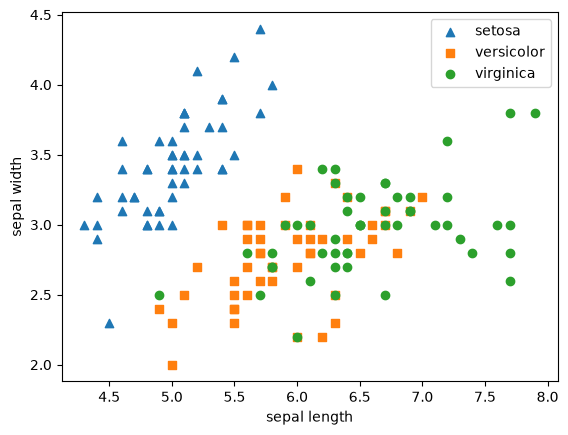

In [3]:
#setosa는 세모, versicolor는 네모, virginica는 동그라미로 표현
markers=['^', 's', 'o']

#setosa의 target 값은 0, versicolor는 1, virginica는 2. 각 target 별로 다른 shape으로 scatter plot
for i, marker in enumerate(markers):
    x_axis_data = irisDF[irisDF['target']==i]['sepal_length']
    y_axis_data = irisDF[irisDF['target']==i]['sepal_width']
    plt.scatter(x_axis_data, y_axis_data, marker=marker,label=iris.target_names[i])

plt.legend()
plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.show()


원래 변수 4개 중 **2개만 골라서** 그린 그림이다. setosa(세모)는 혼자 떨어져 있지만
versicolor와 virginica는 겹쳐 있다. 이게 피처 선택의 한계다 — 두 개만 남기려면
나머지 두 개에 들어 있던 정보를 그냥 버리게 된다. PCA는 네 개를 **섞어서** 두 개를 만든다.


In [4]:
from sklearn.preprocessing import StandardScaler

# Target 값을 제외한 모든 속성 값을 StandardScaler를 이용하여 표준 정규 분포를 가지는 값들로 변환
iris_scaled = StandardScaler().fit_transform(irisDF.iloc[:, :-1])


**PCA 전에는 스케일링이 필수다.** PCA가 분산이 큰 방향을 찾는데, 단위가 큰 변수는 그것만으로
분산이 크다. 길이를 cm로 재던 변수를 mm로 바꾸면 분산이 100배가 되고, PCA는 그 변수 쪽으로
축을 잡아 버린다. 변수의 **단위 차이가 아니라 퍼진 모양**을 비교해야 하니 평균 0·표준편차 1로
맞춰 둔다. 와인 미니프로젝트에서 로지스틱 회귀 앞에 StandardScaler를 둔 것과 같은 이유인데,
거기서는 계수의 크기를 맞추기 위한 것이었고 여기서는 축의 방향 자체가 달라진다.


In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

#fit( )과 transform( ) 을 호출하여 PCA 변환 데이터 반환
pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)
print(iris_pca.shape)


(150, 2)


In [6]:
# PCA 환된 데이터의 컬럼명을 각각 pca_component_1, pca_component_2로 명명
pca_columns=['pca_component_1','pca_component_2']
irisDF_pca = pd.DataFrame(iris_pca, columns=pca_columns)
irisDF_pca['target']=iris.target
irisDF_pca.head(3)


,pca_component_1,pca_component_2,target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0


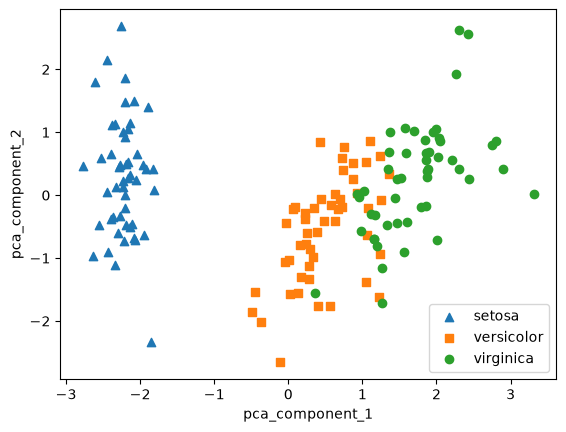

In [7]:
#setosa를 세모, versicolor를 네모, virginica를 동그라미로 표시
markers=['^', 's', 'o']

#pca_component_1 을 x축, pc_component_2를 y축으로 scatter plot 수행.
for i, marker in enumerate(markers):
    x_axis_data = irisDF_pca[irisDF_pca['target']==i]['pca_component_1']
    y_axis_data = irisDF_pca[irisDF_pca['target']==i]['pca_component_2']
    plt.scatter(x_axis_data, y_axis_data, marker=marker,label=iris.target_names[i])

plt.legend()
plt.xlabel('pca_component_1')
plt.ylabel('pca_component_2')
plt.show()


앞의 산점도와 같은 2차원인데 세 품종이 훨씬 잘 갈라진다. 특히 **가로축 하나만으로**
거의 구분이 된다. 네 변수를 조합해 만든 축이 "꽃의 크기" 같은 하나의 방향을 잡아낸 것이다.
세로축은 그에 비하면 폭이 좁다.


In [8]:
print(pca.explained_variance_ratio_)


[0.72962445 0.22850762]


첫 축이 전체 분산의 **약 73%**, 두 번째가 약 23%다. 둘을 합치면 96%쯤 된다.
**변수를 4개에서 2개로 절반 줄였는데 정보는 4%만 잃었다**는 뜻이다.
이 숫자가 PCA에서 몇 개를 남길지 정하는 기준이 된다.


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

rcf = RandomForestClassifier(random_state=156)
scores = cross_val_score(rcf, iris.data, iris.target,scoring='accuracy',cv=3)
print('원본 데이터 교차 검증 개별 정확도:',scores)
print('원본 데이터 평균 정확도:', np.mean(scores))


원본 데이터 교차 검증 개별 정확도: [0.98 0.94 0.96]
원본 데이터 평균 정확도: 0.96


In [10]:
pca_X = irisDF_pca[['pca_component_1', 'pca_component_2']]
scores_pca = cross_val_score(rcf, pca_X, iris.target, scoring='accuracy', cv=3 )
print('PCA 변환 데이터 교차 검증 개별 정확도:',scores_pca)
print('PCA 변환 데이터 평균 정확도:', np.mean(scores_pca))


PCA 변환 데이터 교차 검증 개별 정확도: [0.88 0.88 0.88]
PCA 변환 데이터 평균 정확도: 0.88


0.96에서 0.88로, **8%p나 떨어진다.** 분산은 96%가 남았는데 정확도는 이만큼 잃었다.
분산을 많이 보존한다는 것과 분류에 필요한 정보를 보존한다는 것이 같은 말이 아니라는 뜻이다.

붓꽃은 변수가 4개뿐이라 **차원 축소로 얻을 것이 별로 없다.** 변수 하나하나가 이미 제 몫을
하고 있어서, 줄여서 아끼는 계산량보다 잃는 정보가 크다. PCA 산점도가 보기 좋았던 것은
**시각화**로서의 값이지 모델 성능과는 다른 이야기다.
차원 축소가 값을 하는 건 변수가 수십·수백 개일 때다. 다음 실습이 그 경우다.


### credit card 데이터 세트 PCA 변환

신용카드 사용자의 **다음 달 연체 여부**를 맞히는 데이터다. 변수가 23개이고,
그중 상당수가 6개월치를 월별로 쪼개 놓은 것이라 **서로 많이 닮아 있다.**
PCA를 써 볼 만한 모양이다.


In [11]:
import pandas as pd

df = pd.read_excel('credit_card.xls', sheet_name='Data')
print(df.shape)
df.head(3)


(30001, 25)


,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1


일부러 잘못 읽은 것이다. 열 이름이 `Unnamed: 0`, `X1`, `X2` …로 나오고 **진짜 열 이름이
첫 번째 데이터 행에 들어가 있다.** 엑셀 파일에 머리글이 두 줄이기 때문이다.
그래서 `header=1`로 두 번째 줄을 머리글로 지정하고, 의미 없는 `ID` 열은 `iloc`로 잘라낸다.


In [12]:
# header로 의미없는 첫행 제거, iloc로 기존 id 제거
import pandas as pd

df = pd.read_excel('credit_card.xls', header=1, sheet_name='Data').iloc[0:,1:]
print(df.shape)
df.head(3)


(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [13]:
df.rename(columns={'PAY_0':'PAY_1','default payment next month':'default'}, inplace=True)
y_target = df['default']
X_features = df.drop('default', axis=1)


`PAY_0`을 `PAY_1`로 바꾸는 이유는 **원본의 이름이 틀렸기 때문**이다.
`PAY_2`부터 `PAY_6`까지 있는데 그 앞이 `PAY_0`이라 번호가 끊긴다.
뒤에서 `'PAY_' + str(i) for i in range(1, 7)`로 열 이름을 만들어 쓰려면 `PAY_1`이어야 한다.


In [14]:
X_features.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

<Axes: >

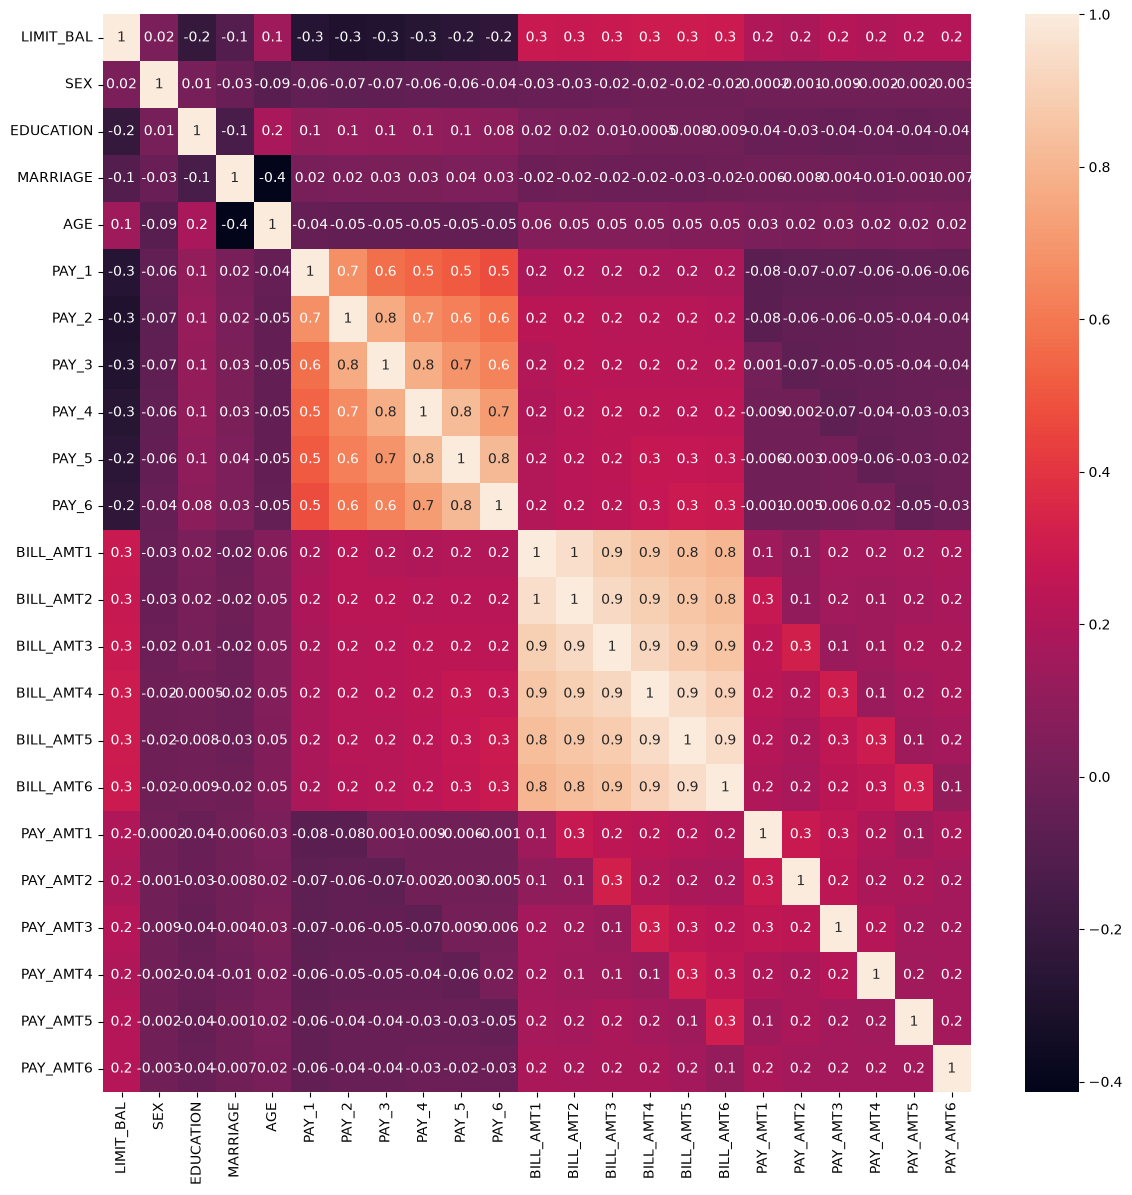

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

corr = X_features.corr()
plt.figure(figsize=(14,14))
sns.heatmap(corr, annot=True, fmt='.1g')


`BILL_AMT1` ~ `BILL_AMT6`(월별 청구액) 블록이 **0.8~0.95**로 서로 붙어 있다.
이번 달 청구액이 많으면 지난달도 많았다는 뜻이니 당연한 결과다.
와인 미니프로젝트에서 상관 행렬을 그려 `free sulfur dioxide`와 `total sulfur dioxide`가
0.72로 묶이는 것을 확인했던 것과 같은 그림인데, **여기는 6개가 한 덩어리로 묶인다.**
이런 변수들은 사실상 같은 정보를 6번 넣고 있는 것이라 PCA로 압축할 여지가 크다.


In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

#BILL_AMT1 ~ BILL_AMT6 까지 6개의 속성명 생성
cols_bill = ['BILL_AMT'+str(i) for i in range(1,7)]
cols_pay = ['PAY_' + str(i) for i in range(1, 7)]
cols_amt = ['PAY_AMT' + str(i) for i in range(1, 7)]
print(cols_bill)
cols_bill.extend(cols_pay)
cols_bill.extend(cols_amt)
print('대상 속성명:',cols_bill)

# 2개의 PCA 속성을 가진 PCA 객체 생성하고, explained_variance_ratio_ 계산 위해 fit( ) 호출
scaler = StandardScaler()
df_cols_scaled = scaler.fit_transform(X_features[cols_bill])
X_features.loc[:, cols_bill] = df_cols_scaled
pca = PCA(n_components=2)
pca.fit(df_cols_scaled)
print('PCA Component별 변동성:', pca.explained_variance_ratio_)


['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
대상 속성명: ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
PCA Component별 변동성: [0.36180187 0.20618472]


**여기서 책 본문과 깃허브 코드가 다르다.** 책에는 `BILL_AMT` 6개만 가지고 PCA를 돌려서
첫 컴포넌트가 **90%**를 설명한다고 나와 있다. 그런데 깃허브 코드는 `cols_bill`에
`PAY_1~6`과 `PAY_AMT1~6`까지 `extend`로 붙여서 **18개**로 돌린다. 그래서 출력이
36%·21%쯤으로 나온다.

직접 6개만 떼어 돌려 보면 `[0.906, 0.051]`이 나와서 책의 90%와 맞는다.
**6개를 1개로 줄여도 정보의 90%가 남는다**는 것이 이 대목의 핵심이고, 18개로 늘리면
성격이 다른 변수(청구액·연체 개월 수·납입액)가 섞이니 한 축으로 모이지 않는 것도 당연하다.
필사는 깃허브 코드를 따랐고, 숫자를 읽을 때는 이 차이를 알고 봐야 한다.


In [17]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rcf = RandomForestClassifier(n_estimators=300, random_state=156)
scores = cross_val_score(rcf, X_features, y_target, scoring='accuracy', cv=3 )

print('CV=3 인 경우의 개별 Fold세트별 정확도:',scores)
print('평균 정확도:{0:.4f}'.format(np.mean(scores)))


CV=3 인 경우의 개별 Fold세트별 정확도: [0.8081 0.8197 0.8232]
평균 정확도:0.8170


In [18]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 원본 데이터셋에 먼저 StandardScaler적용
scaler = StandardScaler()
df_scaled = scaler.fit_transform(X_features)

# 6개의 Component를 가진 PCA 변환을 수행하고 cross_val_score( )로 분류 예측 수행.
pca = PCA(n_components=6)
df_pca = pca.fit_transform(df_scaled)
scores_pca = cross_val_score(rcf, df_pca, y_target, scoring='accuracy', cv=3)

print('CV=3 인 경우의 PCA 변환된 개별 Fold세트별 정확도:',scores_pca)
print('PCA 변환 데이터 셋 평균 정확도:{0:.4f}'.format(np.mean(scores_pca)))


CV=3 인 경우의 PCA 변환된 개별 Fold세트별 정확도: [0.7912 0.7974 0.802 ]
PCA 변환 데이터 셋 평균 정확도:0.7969


**변수 23개를 6개로 줄였는데 정확도는 0.817에서 0.797로 2%p만 떨어진다.**
바로 앞 붓꽃에서는 4개를 2개로 줄이고 8%p를 잃었다. **변수를 4분의 1로 줄였는데
손실은 4분의 1**인 셈이다. 변수가 많고 서로 닮아 있을 때 PCA가 값을 한다는 것이
두 실습을 나란히 놓은 이유다.

다만 연체 데이터는 정답이 0:1로 약 78:22인 **불균형 데이터**다. 전부 "연체 안 함"으로
찍어도 정확도가 78%다. 와인 미니프로젝트에서 품질 등급이 5·6에 몰려 있어 정확도만 보면
안 된다고 정리했던 것과 같은 상황인데, 여기서는 PCA 전후 **비교**가 목적이라
같은 지표로 재는 것 자체는 문제가 없다.


## 6.3 LDA

LDA는 PCA와 하는 일은 같고 **기준이 다르다.**

| | 기준 | 정답(target) |
|---|---|---|
| PCA | 분산이 가장 큰 방향 | 안 쓴다 (비지도) |
| LDA | **클래스가 가장 잘 갈라지는 방향** | **쓴다** (지도) |

LDA는 같은 클래스끼리는 뭉치고(클래스 내 분산은 작게) 다른 클래스끼리는 떨어지도록
(클래스 간 분산은 크게) 축을 잡는다. 두 분산의 **비율**을 최대화하는 문제다.

$$\max \frac{\text{클래스 간 분산}}{\text{클래스 내 분산}}$$

그래서 `fit()`에 **정답을 같이 넣어야 한다.** 이름에 '회귀'가 들어간 로지스틱 회귀가
실제로는 분류 모델이었던 것처럼, 이름에 '분석'이 들어간 LDA는 실제로는 차원 축소다.


In [19]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

iris = load_iris()
iris_scaled = StandardScaler().fit_transform(iris.data)


In [20]:
lda = LinearDiscriminantAnalysis(n_components=2)
lda.fit(iris_scaled, iris.target)
iris_lda = lda.transform(iris_scaled)
print(iris_lda.shape)


(150, 2)


`fit(iris_scaled, iris.target)` — PCA와 달리 **인자가 두 개다.**

여기서 제약이 하나 생긴다. LDA가 만들 수 있는 축은 최대 **클래스 수 − 1개**다.
붓꽃은 품종이 3개라 최대 2개까지만 된다. 클래스 간 분산을 쓰는 구조 때문인데,
점 3개를 지나는 평면이 2차원이면 충분한 것과 같은 이야기다.
PCA는 원래 변수 수까지 만들 수 있으니 이 점이 다르다.


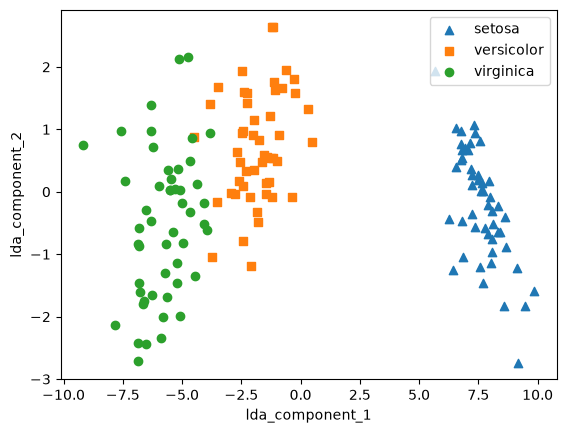

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

lda_columns=['lda_component_1','lda_component_2']
irisDF_lda = pd.DataFrame(iris_lda,columns=lda_columns)
irisDF_lda['target']=iris.target

#setosa는 세모, versicolor는 네모, virginica는 동그라미로 표현
markers=['^', 's', 'o']

#setosa의 target 값은 0, versicolor는 1, virginica는 2. 각 target 별로 다른 shape으로 scatter plot
for i, marker in enumerate(markers):
    x_axis_data = irisDF_lda[irisDF_lda['target']==i]['lda_component_1']
    y_axis_data = irisDF_lda[irisDF_lda['target']==i]['lda_component_2']

    plt.scatter(x_axis_data, y_axis_data, marker=marker,label=iris.target_names[i])

plt.legend(loc='upper right')
plt.xlabel('lda_component_1')
plt.ylabel('lda_component_2')
plt.show()


PCA 산점도와 비교하면 **세 덩어리가 더 단단하게 뭉쳐 있다.** 품종을 알려 주고 축을 잡았으니
당연한 결과다. 그래서 LDA가 항상 좋은 것처럼 보이지만, **정답을 쓴다는 점이 제약이기도 하다.**
정답이 없는 데이터에는 쓸 수 없고, 축을 정답에 맞춰 잡았으니 **그 정답을 맞히는 일 말고
다른 데에 쓰면 편향**이 생긴다. 분류를 목적으로 전처리할 때만 쓰는 도구다.


## 6.4 SVD

PCA는 정방 행렬(공분산 행렬)을 고유값 분해했다. SVD는 **행과 열 수가 달라도** 쓸 수 있는
분해다. $m \times n$ 행렬 $A$를 세 개로 쪼갠다.

$$A = U \Sigma V^T$$

- $U$ ($m \times m$): 서로 직교하는 열벡터
- $\Sigma$ ($m \times n$): 대각선에만 값이 있고 나머지는 0. 대각 원소를 **특이값**이라 한다
- $V^T$ ($n \times n$): 역시 직교

특이값은 **큰 것부터 차례로** 놓인다. 그래서 앞의 몇 개만 남기고 뒤를 잘라도 원본에 가깝게
복원된다. 이게 차원 축소가 되는 원리다.


In [22]:
# numpy의 svd 모듈 import
import numpy as np
from numpy.linalg import svd

# 4X4 Random 행렬 a 생성
np.random.seed(121)
a = np.random.randn(4,4)
print(np.round(a, 3))


[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


In [23]:
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('U matrix:\n',np.round(U, 3))
print('Sigma Value:\n',np.round(Sigma, 3))
print('V transpose matrix:\n',np.round(Vt, 3))


(4, 4) (4,) (4, 4)
U matrix:
 [[-0.079 -0.318  0.867  0.376]
 [ 0.383  0.787  0.12   0.469]
 [ 0.656  0.022  0.357 -0.664]
 [ 0.645 -0.529 -0.328  0.444]]
Sigma Value:
 [3.423 2.023 0.463 0.079]
V transpose matrix:
 [[ 0.041  0.224  0.786 -0.574]
 [-0.2    0.562  0.37   0.712]
 [-0.778  0.395 -0.333 -0.357]
 [-0.593 -0.692  0.366  0.189]]


`Sigma`가 행렬이 아니라 **1차원 배열**로 나온다. 대각선 말고는 전부 0이니
넘파이가 대각 원소만 돌려주는 것이다. 다시 곱할 때는 `np.diag()`로 행렬 모양을 만들어야 한다.


In [24]:
# Sima를 다시 0 을 포함한 대칭행렬로 변환
Sigma_mat = np.diag(Sigma)
a_ = np.dot(np.dot(U, Sigma_mat), Vt)
print(np.round(a_, 3))


[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


원본 `a`와 같다. 분해했다가 다시 곱하면 원래대로 돌아온다는 확인이다.
여기까지는 정보를 하나도 버리지 않았다.


In [25]:
a[2] = a[0] + a[1]
a[3] = a[0]
print(np.round(a,3))


[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


In [26]:
# 다시 SVD를 수행하여 Sigma 값 확인
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('Sigma Value:\n',np.round(Sigma,3))


(4, 4) (4,) (4, 4)
Sigma Value:
 [2.663 0.807 0.    0.   ]


**일부러 3행을 1행+2행으로, 4행을 1행과 같게 만들었다.** 그러자 특이값 4개 중
**뒤의 2개가 0**이 된다. 겉으로는 4×4 행렬인데 실제로 독립적인 행은 2개뿐이라는 뜻이다
(행렬의 랭크가 2다).

이게 상관이 높은 변수가 많은 데이터에서 벌어지는 일이다. 바로 앞 6.2의 `BILL_AMT` 6개가
서로 0.9씩 상관되어 있었는데, 그건 "6개인 척하지만 실제로는 1~2개"라는 말과 같다.
**특이값이 그 사실을 숫자로 보여 준다.**


In [27]:
# U 행렬의 경우는 Sigma와 내적을 수행하므로 Sigma의 앞 2행에 대응되는 앞 2열만 추출
U_ = U[:, :2]
Sigma_ = np.diag(Sigma[:2])
# V 전치 행렬의 경우는 앞 2행만 추출
Vt_ = Vt[:2]
print(U_.shape, Sigma_.shape, Vt_.shape)
# U, Sigma, Vt의 내적을 수행하며, 다시 원본 행렬 복원
a_ = np.dot(np.dot(U_,Sigma_), Vt_)
print(np.round(a_, 3))


(4, 2) (2, 2) (2, 4)
[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


**앞의 2개만 남겼는데 원본이 그대로 복원된다.** 버린 2개가 0이었으니 손실이 없다.
행렬을 저장할 때 4×4=16개 대신 4×2 + 2 + 2×4 = 14개만 들고 있으면 되는 셈이고,
행과 열이 클수록 이 차이가 커진다.


### Truncated SVD

위에서는 분해를 다 해 놓고 뒤를 잘랐다. **Truncated SVD는 처음부터 앞의 $k$개만 구한다.**
전부 구하는 것보다 빠르고, 특이값이 0이 아닌 것까지 잘라 버리니 복원은 근사가 된다.


In [28]:
import numpy as np
from scipy.sparse.linalg import svds
from scipy.linalg import svd

# 원본 행렬을 출력하고, SVD를 적용할 경우 U, Sigma, Vt 의 차원 확인
np.random.seed(121)
matrix = np.random.random((6, 6))
print('원본 행렬:\n',matrix)
U, Sigma, Vt = svd(matrix, full_matrices=False)
print('\n분해 행렬 차원:',U.shape, Sigma.shape, Vt.shape)
print('\nSigma값 행렬:', Sigma)

# Truncated SVD로 Sigma 행렬의 특이값을 4개로 하여 Truncated SVD 수행.
num_components = 4
U_tr, Sigma_tr, Vt_tr = svds(matrix, k=num_components)
print('\nTruncated SVD 분해 행렬 차원:',U_tr.shape, Sigma_tr.shape, Vt_tr.shape)
print('\nTruncated SVD Sigma값 행렬:', Sigma_tr)
matrix_tr = np.dot(np.dot(U_tr,np.diag(Sigma_tr)), Vt_tr)  # output of TruncatedSVD

print('\nTruncated SVD로 분해 후 복원 행렬:\n', matrix_tr)


원본 행렬:
 [[0.11133083 0.21076757 0.23296249 0.15194456 0.83017814 0.40791941]
 [0.5557906  0.74552394 0.24849976 0.9686594  0.95268418 0.48984885]
 [0.01829731 0.85760612 0.40493829 0.62247394 0.29537149 0.92958852]
 [0.4056155  0.56730065 0.24575605 0.22573721 0.03827786 0.58098021]
 [0.82925331 0.77326256 0.94693849 0.73632338 0.67328275 0.74517176]
 [0.51161442 0.46920965 0.6439515  0.82081228 0.14548493 0.01806415]]

분해 행렬 차원: (6, 6) (6,) (6, 6)

Sigma값 행렬: [3.2535007  0.88116505 0.83865238 0.55463089 0.35834824 0.0349925 ]

Truncated SVD 분해 행렬 차원: (6, 4) (4,) (4, 6)

Truncated SVD Sigma값 행렬: [0.55463089 0.83865238 0.88116505 3.2535007 ]

Truncated SVD로 분해 후 복원 행렬:
 [[0.19222941 0.21792946 0.15951023 0.14084013 0.81641405 0.42533093]
 [0.44874275 0.72204422 0.34594106 0.99148577 0.96866325 0.4754868 ]
 [0.12656662 0.88860729 0.30625735 0.59517439 0.28036734 0.93961948]
 [0.23989012 0.51026588 0.39697353 0.27308905 0.05971563 0.57156395]
 [0.83806144 0.78847467 0.93868685 0.72673231 

이번엔 난수 행렬이라 특이값 6개가 모두 0이 아니다. 그중 4개만 쓰니 복원 행렬이
원본과 **조금씩 다르다.** 앞의 예시처럼 딱 맞지 않는 것이 정상이고, 이 차이가
"정보를 버린 양"이다. `svds`가 돌려주는 특이값은 **작은 것부터** 정렬돼 있는 점도 다르다.


### 사이킷런 TruncatedSVD 클래스를 이용한 변환


Text(0, 0.5, 'TruncatedSVD Component 2')

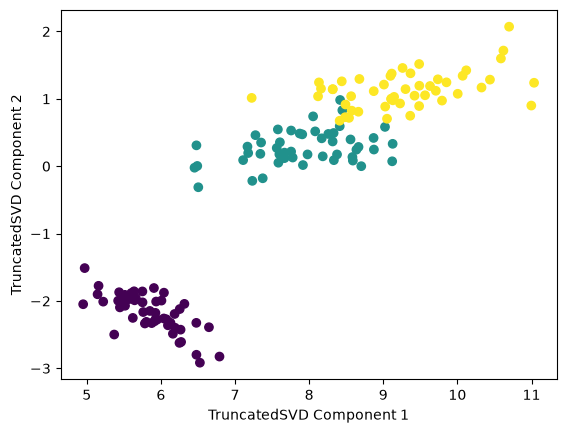

In [29]:
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data
# 2개의 주요 component로 TruncatedSVD 변환
tsvd = TruncatedSVD(n_components=2)
tsvd.fit(iris_ftrs)
iris_tsvd = tsvd.transform(iris_ftrs)

# Scatter plot 2차원으로 TruncatedSVD 변환 된 데이터 표현. 품종은 색깔로 구분
plt.scatter(x=iris_tsvd[:,0], y= iris_tsvd[:,1], c= iris.target)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')


Text(0.5, 1.0, 'PCA Transformed')

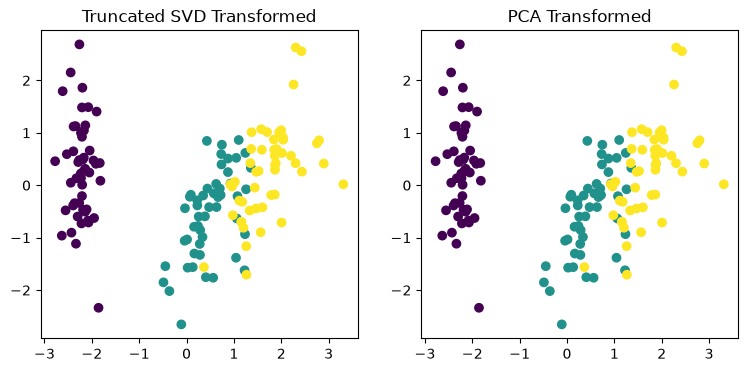

In [30]:
from sklearn.preprocessing import StandardScaler

# iris 데이터를 StandardScaler로 변환
scaler = StandardScaler()
iris_scaled = scaler.fit_transform(iris_ftrs)

# 스케일링된 데이터를 기반으로 TruncatedSVD 변환 수행
tsvd = TruncatedSVD(n_components=2)
tsvd.fit(iris_scaled)
iris_tsvd = tsvd.transform(iris_scaled)

# 스케일링된 데이터를 기반으로 PCA 변환 수행
pca = PCA(n_components=2)
pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)

# TruncatedSVD 변환 데이터를 왼쪽에, PCA변환 데이터를 오른쪽에 표현
fig, (ax1, ax2) = plt.subplots(figsize=(9,4), ncols=2)
ax1.scatter(x=iris_tsvd[:,0], y= iris_tsvd[:,1], c= iris.target)
ax2.scatter(x=iris_pca[:,0], y= iris_pca[:,1], c= iris.target)
ax1.set_title('Truncated SVD Transformed')
ax2.set_title('PCA Transformed')


In [31]:
print((iris_pca - iris_tsvd).mean())
print((pca.components_ - tsvd.components_).mean())


2.3390433108912606e-15
9.71445146547012e-17


**두 그림이 사실상 같고, 차이의 평균이 0에 가깝다.** 스케일링(평균을 0으로 맞추는 것)을
거치면 **TruncatedSVD와 PCA가 같은 변환**이 된다. PCA는 공분산 행렬을 분해하는데,
평균이 0이면 공분산 행렬이 $X^T X$에 비례하고 그건 $X$의 SVD로 바로 얻어진다.

그래서 사이킷런의 PCA도 내부에서 SVD를 쓴다. 그러면 둘을 왜 나눠 두었는가 하면,
**TruncatedSVD는 평균을 빼지 않기 때문**이다. 평균을 빼면 0이 대부분인 희소 행렬이
빽빽해져서 메모리가 터진다. 텍스트 데이터처럼 0이 많은 행렬에는 TruncatedSVD를 쓴다.
스케일링을 하지 않은 첫 번째 그림이 PCA 결과와 모양이 다른 것도 이 때문이다.


## 6.5 NMF

NMF는 SVD와 비슷하게 행렬을 쪼개지만 조건이 하나 붙는다.
**원본과 분해된 두 행렬 모두 원소가 0 이상**이어야 한다.

$$V \approx W H \quad (V, W, H \ge 0)$$

음수를 허용하지 않으면 "더해서 만든다"는 해석만 남는다. SVD는 "+3배, −2배" 같은 조합이
가능해서 축의 의미를 읽기 어렵지만, NMF는 빼는 것이 없으니 **원래 성분들의 합**으로 읽힌다.
얼굴 사진을 NMF로 쪼개면 눈·코·입 같은 부분이 나오는 식이다.

조건이 붙은 만큼 쓸 수 있는 데이터도 제한된다. 횟수·금액·픽셀 밝기처럼 **음수가 없는 데이터**여야 한다.


Text(0, 0.5, 'NMF Component 2')

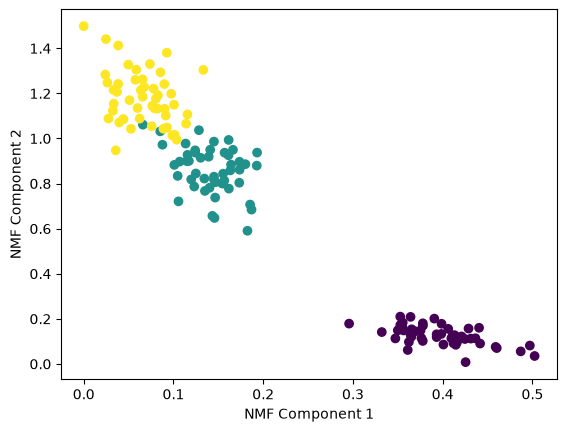

In [32]:
from sklearn.decomposition import NMF
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data
nmf = NMF(n_components=2)
nmf.fit(iris_ftrs)
iris_nmf = nmf.transform(iris_ftrs)
plt.scatter(x=iris_nmf[:,0], y= iris_nmf[:,1], c= iris.target)
plt.xlabel('NMF Component 1')
plt.ylabel('NMF Component 2')


붓꽃의 길이·폭은 전부 양수라 NMF를 쓸 수 있다. 여기서는 **스케일링을 하지 않는다** —
표준화를 하면 음수가 생겨서 NMF 조건을 깨기 때문이다. 산점도는 품종이 갈라지긴 하지만
PCA나 LDA보다 경계가 흐리다. NMF의 쓸모는 분류 전처리가 아니라 **쪼갠 성분을 해석하는 것**과
**추천**에 있다. 사용자×아이템 평점 행렬을 사용자 요인과 아이템 요인으로 쪼개는
행렬 분해가 NMF 계열이고, 9장 추천 시스템에서 다시 나온다.


## 6.6 정리

| 절 | 방법 | 기준 | 정답 사용 | 쓰는 곳 |
|---|---|---|---|---|
| 6.2 | **PCA** | 분산이 가장 큰 방향 | 안 씀 | 변수가 많고 서로 닮은 정형 데이터 |
| 6.3 | **LDA** | 클래스가 잘 갈라지는 방향 | **씀** | 분류 전처리 (축 최대 클래스 수 − 1) |
| 6.4 | **SVD** | 특이값이 큰 순서 | 안 씀 | 정방 행렬이 아닌 경우, 희소 행렬 |
| 6.5 | **NMF** | 음수 없는 분해 | 안 씀 | 성분 해석, 추천 (행렬 분해) |

네 방법이 하는 일은 모두 같다. **원래 변수들을 조합해 더 적은 수의 새 축을 만드는 것**이다.
갈리는 지점은 "무엇을 기준으로 축을 잡는가"뿐이다.

실습에서 확인한 것은 두 가지다.

- **차원 축소의 이득은 변수가 많고 서로 닮아 있을 때 나온다.** 붓꽃(4개 → 2개)에서는 정확도가
  0.96에서 0.88로 8%p 떨어졌지만, 신용카드(23개 → 6개)에서는 0.817에서 0.797로 2%p만 떨어졌다.
- **PCA 전에는 스케일링이 필요하고, TruncatedSVD는 그 스케일링을 생략한 PCA다.**
  평균을 0으로 맞추면 둘은 같은 변환이 된다.


## 느낀 점

**상관 행렬을 보던 눈과 차원 축소가 같은 것을 보고 있었다.** 와인 미니프로젝트에서 상관
행렬을 그려 `free sulfur dioxide`와 `total sulfur dioxide`가 0.72로 묶이는 것을 확인하고
"둘 중 하나는 빼도 되지 않을까" 하다가 결국 그냥 뒀다. 트리 모델이라 영향이 적다는 이유였다.
이번에 신용카드 데이터에서 `BILL_AMT` 6개가 0.9씩 묶여 있는 것을 보고 PCA를 돌리니
첫 축 하나가 90%를 설명했다. **상관이 높다는 말과 실제 차원이 낮다는 말이 같은 말**이었다.
그리고 6.4에서 일부러 종속인 행을 만들어 SVD를 돌렸을 때 특이값 뒤쪽 2개가 0이 되는 걸
보고서야 그게 왜 같은 말인지 눈으로 이해했다. 상관 행렬은 두 변수씩 보여 주는 것이고,
특이값은 **전체를 한 번에** 보여 준다.

**버릴 정보의 양을 숫자로 정할 수 있다는 게 새로웠다.** 지금까지 변수를 뺄지 말지는 감으로
정했다. 상관이 0.9니까 빼자, 결측이 1,453건이니까 지우자 하는 식이었다.
`explained_variance_ratio_`는 **"이만큼 줄이면 이만큼 잃는다"를 미리 알려 준다.**
붓꽃에서 4개를 2개로 줄여도 96%가 남는다는 걸 보고 줄인 것과, 그냥 두 개를 골라 버린 것은
다른 작업이다. 5장에서 지표를 먼저 읽고 전처리를 정했던 것과 비슷하게,
여기서는 손실률을 먼저 보고 차원을 정한다.

**다만 그 숫자를 너무 믿으면 안 된다는 것도 같이 봤다.** 붓꽃은 분산을 96% 지켰는데
정확도는 0.96에서 0.88로 떨어졌다. **분산이 큰 방향이 꼭 품종을 가르는 방향은 아니다.**
PCA가 정답을 안 보고 축을 잡으니 당연한 일인데, 그래서 6.3의 LDA가 따로 있는 것이고
`explained_variance_ratio_`는 "얼마나 잃을지"의 상한이 아니라 참고값으로 봐야 한다.

**LDA가 정답을 쓴다는 점이 계속 걸렸다.** 처음 산점도를 보고는 PCA보다 잘 갈라지니
LDA를 쓰면 되지 않나 싶었다. 그런데 축을 정답에 맞춰 잡아 놓고 그 정답을 맞히는 모델을
학습하면, 교차검증을 해도 이미 테스트 정보가 축에 섞여 들어간 상태다.
`fit(X, y)`에 `y`가 들어가는 변환은 **학습 데이터에서만 fit해야 한다**는 것이
스케일러와 같은 원칙인데, LDA는 그 위험이 더 크다.
미니프로젝트에서 StandardScaler를 전체 데이터에 먼저 적용했던 적이 있는데,
같은 실수를 LDA로 했다면 결과가 훨씬 크게 틀어졌을 것 같다.

**PCA와 TruncatedSVD가 같은 변환이라는 대목이 제일 재미있었다.** 두 절을 따로 배우고
클래스도 따로 있는데, 스케일링을 거치면 결과 차이의 평균이 0이 된다.
그러면서도 둘을 나눠 둔 이유가 **희소 행렬에서는 평균을 빼면 안 되기 때문**이라는 것이,
수학적으로 같은 것과 구현상 같은 것이 다르다는 걸 보여 준다.
8장 텍스트 분석에서 단어 행렬을 다룰 때 왜 TruncatedSVD를 쓰는지 미리 알게 된 셈이다.

**깃허브 코드와 책 본문이 다른 곳이 있었다.** 6.2의 `cols_bill`에 `PAY`와 `PAY_AMT`가
`extend`로 붙어 있어서 책에 적힌 90%가 아니라 36%가 출력된다. 처음엔 내가 잘못 돌린 줄 알고
여러 번 다시 돌렸는데, 변수 6개만 떼어 돌려 보니 `[0.906, 0.051]`로 책과 맞았다.
**출력 숫자가 책과 다르면 코드가 무엇을 입력으로 받았는지를 먼저 봐야 한다.**
필사는 코드를 그대로 따르되 이 차이를 적어 두는 쪽으로 정리했다.
